In [1]:
import sys,os
os.environ["JAX_PLATFORMS"] = "cpu"
from dadapy.hamming import Hamming,BID

sys.path.append('../')
import numpy as np

from utils import (
                   makefolder,
                   emb_dims,
                   depths,
                   )
from datapaths import *
import matplotlib.pyplot as plt

depths = {"deepseek":61,
          "llama":32}
emb_dims = {"deepseek":7168,
          "llama":4096}

rcpsize = 18
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

/home/acevedo/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


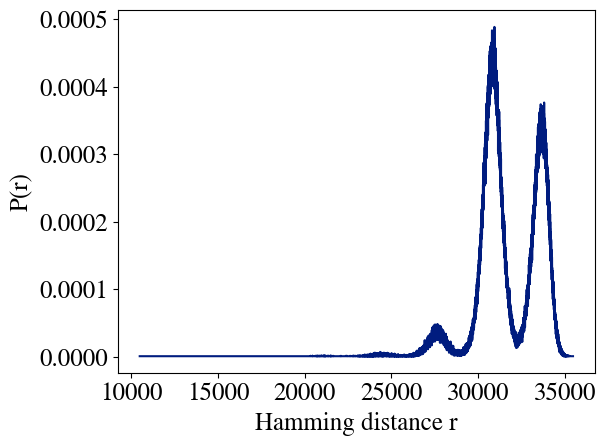

In [6]:
avg_flags = [0]
n_tokens_list = [10]
Nbits_list = [1]
# layers = np.setdiff1d(np.arange(3, 60 + 1, 1, dtype=int), np.arange(1, 60 + 1, 5, dtype=int))

model = 'deepseek'
# model = 'llama'
_model = 'DeepSeek-V3' if model == 'deepseek' else 'LLama3.1-8b'
n_files = 500
languageA = 'english'
languageB = 'spanish'
languages = ['source']
min_token_length = 40
seed_list = [0]
layers = np.arange(2,depths[model]+1,1,dtype=int)
layers = [1]


fig,ax = plt.subplots(1)
start = 0
for seed_id, jack_seed in enumerate(seed_list):
  for language_id,language in enumerate(languages):
    output_folder0 = makefolder(base=f'./results/santiago/',
                                create_folder=True,
                                modelA=model,
                                modelB=model,
                                n_files=n_files,
                                min_token_length=min_token_length,
                                languageA=languageA,
                                languageB=languageB,
                                language=language,
                                )
    for n_tokens_id, n_tokens in enumerate(n_tokens_list):
        n_features = n_tokens * emb_dims[model]
        for Nbits_id, Nbits in enumerate(Nbits_list):
            for avg_tokens in avg_flags:
                for A_counter,layer_idx in enumerate(layers):               
                    H = Hamming(crossed_distances=1)
                    histfolder = makefolder(base=output_folder0 + '/hist/',
                                            n_tokens=n_tokens,
                                            layer_idx=layer_idx,
                                            seed=jack_seed,
                    )
                    H.D_histogram(compute_flag=0,
                                resultsfolder=histfolder,
                                )
                    ax.plot(H.D_values[start:],H.D_probs[start:],label=f'{language}')
                    # ax.set_yscale('log')
                    ax.set_ylabel('P(r)')
                    ax.set_xlabel('Hamming distance r')

In [ ]:
# for layer_idx in layers:
#   print(f'{layer_idx=}')
#   for language_id,language in enumerate(languages):
#     output_folder0 = makefolder(base=f'./results/santiago/',
#                                 create_folder=True,
#                                 modelA=model,
#                                 modelB=model,
#                                 n_files=n_files,
#                                 min_token_length=min_token_length,
#                                 languageA=languageA,
#                                 languageB=languageB,
#                                 language=language,
#                                 )
#     H = Hamming(crossed_distances=1)
#     histfolder = makefolder(base=output_folder0 + '/hist/',
#                             n_tokens=n_tokens,
#                             layer_idx=layer_idx,
#                             seed=jack_seed,)
#     H.D_histogram(compute_flag=0,
#                 resultsfolder=histfolder,
#                 )
#     alphamin = .15    
#     alphamax_list = [.4] #np.arange(.55,.55+eps,.05)        
#     Nsteps = int(1e5)   
#     export_results = 1  
#     export_logKLs = 1   
#     optfolder0 = makefolder(base=output_folder0 + '/opt/',
#                         n_tokens=n_tokens,
#                         layer_idx=layer_idx,
#                         seed=jack_seed,
#                         )
#     steps_initial = jnp.array([5E-1,1E-1,5E-2,1E-2],dtype=jnp.double)
#     for alphamax_id,alphamax in enumerate(alphamax_list):
#         B = BID(
#             H=H,
#             alphamin=alphamin,
#             alphamax=alphamax,
#             Nsteps=Nsteps,
#             export_results=export_results,
#             export_logKLs=export_logKLs,
#             optfolder0=optfolder0,
#             L=n_features,
#             steps_initial=steps_initial,
#         )
#         B.computeBID() 

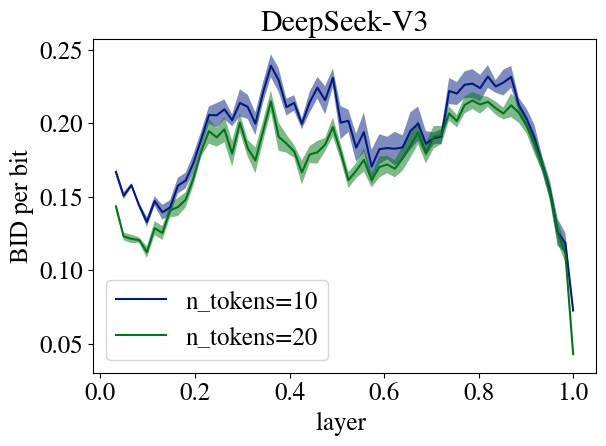

In [3]:
fig,ax = plt.subplots(1,)#figsize=(12,6))
figsfolder = makefolder(base=f'./results/figs/{model}/',
                        create_folder=True,
                        n_files=n_files,
                        )

alphamin = .15    
alphamax = .4
Nsteps = int(1e5)   
export_results = 1  
export_logKLs = 1   
layers = np.arange(2,depths[model]+1,1,dtype=int)
if model == 'llama':
  seed_list = [0,1,2,3]
  n_tokens_list = [1,10,20]
else:
  seed_list = [0,1,2,3,4,5,6,7,8,9]
  n_tokens_list = [10,20]

BIDs = np.zeros(shape=(len(seed_list),
                       len(layers),
                       len(n_tokens_list))
                )
for n_tokens_id,n_tokens in enumerate(n_tokens_list):
  n_features = n_tokens * emb_dims[model]
  for seed_id, jack_seed in enumerate(seed_list):
    for l_index,layer_idx in enumerate(layers):
      output_folder0 = makefolder(base=f'./results/santiago/',
                                  create_folder=True,
                                  modelA=model,
                                  modelB=model,
                                  n_files=n_files,
                                  min_token_length=min_token_length,
                                  languageA=languageA,
                                  languageB=languageB,
                                  language=language,
                                  )
      optfolder0 = makefolder(base=output_folder0 + '/opt/',
                          n_tokens=n_tokens,
                          layer_idx=layer_idx,
                          seed=jack_seed,)
      B = BID(
            alphamin=alphamin,
            alphamax=alphamax,
            optfolder0=optfolder0,
            Nsteps=Nsteps,
            )
      rmax,BIDs[seed_id,l_index,n_tokens_id],d_1,logKL = B.load_results()
      # BIDs[seed_id,l_index,n_tokens_id] = BIDs[seed_id,l_index,n_tokens_id] * n_features
      # remp,Pemp,Pmodel = B.load_fit()
      # logKLs = B.load_logKLs_opt()
    BIDs[np.where(BIDs<0)] = np.nan
    # ax.errorbar(layers/layers[-1],
    #         BIDs[seed_id,:,n_tokens_id],
    # )
  # ax.errorbar(layers,
  #         np.nanmean(BIDs[:,:,n_tokens_id],axis=0),
  #         np.nanstd(BIDs[:,:,n_tokens_id],axis=0),
  #         label=f'{n_tokens=}',
  #         )
  # BIDs[:,:5,0] = np.nan
  ax.plot(layers/depths[model],
          np.nanmean(BIDs[:,:,n_tokens_id],axis=0),
          label=f'{n_tokens=}',
          )
  ax.fill_between(layers/depths[model],
          np.nanmean(BIDs[:,:,n_tokens_id],axis=0)-np.nanstd(BIDs[:,:,n_tokens_id],axis=0),
          np.nanmean(BIDs[:,:,n_tokens_id],axis=0)+np.nanstd(BIDs[:,:,n_tokens_id],axis=0),
          alpha=0.5
          )

ax.set_xlabel('layer ')
ax.set_ylabel('BID per bit')
ax.legend()
ax.set_title(f'{_model}')
plt.show()
fig.savefig(f'{figsfolder}BID.pdf',
              bbox_inches='tight',
              )

In [ ]:
fig,ax = plt.subplots(1,2,figsize=(12,6))

n_tokens = 1
jack_seed = 6
for layer_idx in layers[40:50][::1]:
  for language_id,language in enumerate(languages):
    output_folder0 = makefolder(base=f'./results/santiago/',
                                create_folder=True,
                                modelA=model,
                                modelB=model,
                                n_files=n_files,
                                min_token_length=min_token_length,
                                languageA=languageA,
                                languageB=languageB,
                                language=language,  
    )
    optfolder0 = makefolder(base=output_folder0 + '/opt/',
                        n_tokens=n_tokens,
                        layer_idx=layer_idx,
                        seed=jack_seed,)
    B = BID(
          alphamin=alphamin,
          alphamax=alphamax,
          optfolder0=optfolder0,
          Nsteps=Nsteps,
          )
    rmax,d_0,d_1,logKL = B.load_results()
    remp,Pemp,Pmodel = B.load_fit()
    logKLs = B.load_logKLs_opt()

    ax[0].plot(remp,Pemp,'x')
    ax[0].plot(remp,Pmodel,'black','..')
    ax[0].set_yscale('log')
    ax[0].set_xscale('log')
    ax[0].set_xlabel('Hamming distance r')
    ax[0].set_ylabel('P(r)')
    # plt.legend()
    ax[1].plot(logKLs)
    ax[1].set_ylabel('logKL')
    ax[1].set_xlabel('optimization step')
plt.show()
